# Journey or audience? Shopper-type analysis of the LG–Samsung TV gap

**Question this notebook answers:** is LG's lower TV conversion explained by *who* views LG TVs
(the shopper mix) or does a gap remain among comparable shoppers, which would point to the journey itself?

**Why:** Anahi's dual-brand check found that among users who considered both brands the LG–Samsung gap almost
disappears. This notebook tests that finding systematically.

**Same cohort rules as `Edoardo_notebook.ipynb`:** one row = user × session × product with a view; first view
sets price and time; cart and purchase must happen strictly later in the same key.

| Block | Purpose |
|---|---|
| S01–S02 | Load data and rebuild the TV LG/Samsung cohort (should match 74,712 rows) |
| S03 | Label each user: LG-only, Samsung-only or cross-shopper (viewed both) |
| S04 | Shopper mix: where each brand's rows come from |
| S05 | KPIs by shopper type and brand |
| S06 | Mix decomposition: how much of the raw gap the shopper mix explains |
| S07 | Browsing profile of each shopper type (rough intent proxies) |
| S08 | Logit models with and without shopper type (three outcomes) |
| S09 | Robustness: shopper type known at first view (prior exposure) |
| S10 | How to read the results |

Shopper types describe observed browsing in this sample. They are not demographics and not causes.

In [1]:
# S01. Load the events from the private data folder (same path as the other notebooks).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
events = pd.read_csv(DATA_DIR / 'electronics_market_behavior.csv')
events['event_time'] = pd.to_datetime(events['event_time'], utc=True)
key = ['user_id', 'session_id', 'product_id']
televisions = events[events['product_category'] == 'tv']
tv = televisions[televisions['brand'].isin(['lg', 'samsung'])].copy()
print('All events:', len(events), '| TV events:', len(televisions), '| LG/Samsung TV events:', len(tv))

All events: 649605 | TV events: 212303 | LG/Samsung TV events: 135411


In [2]:
# S02. Rebuild the consideration table exactly as in Edoardo_notebook cells 04-05.
views = tv[tv['event_type'] == 'view']
first_views = views.sort_values('event_time', kind='stable').drop_duplicates(key)
first_views = first_views[key + ['brand', 'price', 'event_time']].rename(
    columns={'price': 'initial_price', 'event_time': 'first_view'})
last_purchases = tv[tv['event_type'] == 'purchase'].groupby(key)['event_time'].max().reset_index(name='last_purchase')
carts = tv[tv['event_type'] == 'cart'].merge(first_views[key + ['first_view']], on=key)
carts = carts[carts['event_time'] > carts['first_view']]
first_carts = carts.groupby(key)['event_time'].min().reset_index(name='first_cart')

cohort = first_views.merge(first_carts, on=key, how='left').merge(last_purchases, on=key, how='left')
cohort['has_cart'] = cohort['first_cart'].notna().astype(int)
cohort['purchase_after_cart'] = (cohort['last_purchase'] > cohort['first_cart']).astype(int)
cohort['Y'] = (cohort['last_purchase'] > cohort['first_view']).astype(int)
cohort['LG'] = (cohort['brand'] == 'lg').astype(int)
cohort['log_price'] = np.log(cohort['initial_price'])
cohort['entry_month'] = cohort['first_view'].dt.strftime('%Y-%m')
assert not cohort.duplicated(key).any()
print('Considerations:', len(cohort), '| Users:', cohort['user_id'].nunique(), '| Purchases:', cohort['Y'].sum())
print('Reference from the group audit: 74,712 considerations, 35,871 users, 2,150 purchases.')

Considerations: 74712 | Users: 35871 | Purchases: 2150
Reference from the group audit: 74,712 considerations, 35,871 users, 2,150 purchases.


## S03. Shopper types

A user is a **cross-shopper** if they have at least one consideration of each brand during the two months,
otherwise **LG-only** or **Samsung-only**. For the models we use the binary `cross_shopper` (1/0): the three-way
label cannot enter a model alongside brand, because "LG-only" rows are always LG rows.

In [3]:
# S03. Label each user by the TV brands (LG/Samsung) they considered.
user_brands = cohort.groupby('user_id')['brand'].agg(['nunique', 'first'])
user_type = pd.Series(np.where(user_brands['nunique'] == 2, 'cross_shopper', user_brands['first'] + '_only'),
                      index=user_brands.index)
type_order = ['lg_only', 'samsung_only', 'cross_shopper']
cohort['shopper_type'] = pd.Categorical(cohort['user_id'].map(user_type), categories=type_order)
cohort['cross_shopper'] = (cohort['shopper_type'] == 'cross_shopper').astype(int)
display(pd.DataFrame({'users': user_type.value_counts().reindex(type_order),
                      'rows': cohort['shopper_type'].value_counts().reindex(type_order)}))

,users,rows
lg_only,6544,10019
samsung_only,22963,36666
cross_shopper,6364,28027


In [4]:
# S04. Shopper mix: what share of each brand's considerations comes from cross-shoppers?
mix = pd.crosstab(cohort['brand'], cohort['cross_shopper'].map({0: 'single_brand', 1: 'cross_shopper'}))
mix_pct = 100 * mix.div(mix.sum(axis=1), axis=0)
display(pd.concat({'rows': mix, 'share_of_brand_rows_pct': mix_pct}, axis=1))
# Interpretation: if LG draws a much larger share of its rows from cross-shoppers, and cross-shoppers convert
# less per row (they browse more), LG's average rate is pulled down by its audience mix.

rows              share_of_brand_rows_pct             
cross_shopper cross_shopper single_brand           cross_shopper single_brand
brand                                                                        
lg                    12194        10019                  54.896       45.104
samsung               15833        36666                  30.159       69.841

In [5]:
# S05. KPIs by shopper type and brand, each with explicit numerator and denominator.
def kpi_table(df, by):
    g = df.groupby(by, observed=True).agg(
        considerations=('Y', 'size'), users=('user_id', 'nunique'), carts=('has_cart', 'sum'),
        purchases_after_cart=('purchase_after_cart', 'sum'), purchases=('Y', 'sum'))
    g['view_to_cart_pct'] = 100 * g['carts'] / g['considerations']
    g['cart_to_purchase_pct'] = 100 * g['purchases_after_cart'] / g['carts'].replace(0, np.nan)
    g['view_to_purchase_pct'] = 100 * g['purchases'] / g['considerations']
    return g

rate_columns = ['view_to_cart_pct', 'cart_to_purchase_pct', 'view_to_purchase_pct']
by_type = kpi_table(cohort, ['shopper_type', 'brand'])
display(by_type.round(2))

overall = kpi_table(cohort, ['brand'])
cross = by_type.loc['cross_shopper']
gaps = pd.DataFrame({
    'all_shoppers': overall.loc['lg', rate_columns] - overall.loc['samsung', rate_columns],
    'single_brand_shoppers': by_type.loc[('lg_only', 'lg'), rate_columns] - by_type.loc[('samsung_only', 'samsung'), rate_columns],
    'cross_shoppers': cross.loc['lg', rate_columns] - cross.loc['samsung', rate_columns]})
print('LG minus Samsung, percentage points (raw, unadjusted):')
display(gaps.round(2))
# The cross_shoppers column should reproduce Anahi's dual-brand check (about -0.04 pp view-to-purchase).

considerations  users  carts  purchases_after_cart  \
shopper_type  brand                                                         
lg_only       lg                10019   6544    633                   237   
samsung_only  samsung           36666  22963   2733                  1155   
cross_shopper lg                12194   6364    440                   137   
              samsung           15833   6364    578                   175   

                       purchases  view_to_cart_pct  cart_to_purchase_pct  \
shopper_type  brand                                                        
lg_only       lg             336             6.320                37.440   
samsung_only  samsung       1420             7.450                42.260   
cross_shopper lg             169             3.610                31.140   
              samsung        225             3.650                30.280   

                       view_to_purchase_pct  
shopper_type  brand                          
lg_only       lg                      3.350  
samsung_only  samsung                 3.870  
cross_shopper lg                      1.390  
              samsung                 1.420

LG minus Samsung, percentage points (raw, unadjusted):


,all_shoppers,single_brand_shoppers,cross_shoppers
view_to_cart_pct,-1.480,-1.140,-0.040
cart_to_purchase_pct,-5.310,-4.820,0.860
view_to_purchase_pct,-0.860,-0.520,-0.040


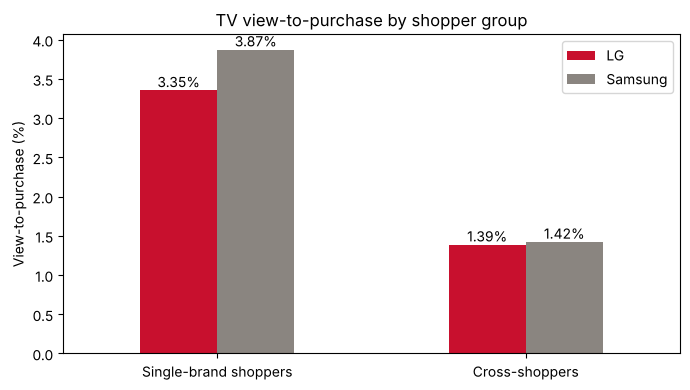

In [6]:
# S05b. Chart: view-to-purchase by shopper group and brand.
plot_data = pd.DataFrame({
    'LG': [by_type.loc[('lg_only', 'lg'), 'view_to_purchase_pct'], cross.loc['lg', 'view_to_purchase_pct']],
    'Samsung': [by_type.loc[('samsung_only', 'samsung'), 'view_to_purchase_pct'], cross.loc['samsung', 'view_to_purchase_pct']]},
    index=['Single-brand shoppers', 'Cross-shoppers'])
ax = plot_data.plot.bar(color=['#C8102E', '#8A8580'], rot=0, figsize=(7, 4))
ax.set_ylabel('View-to-purchase (%)')
ax.set_title('TV view-to-purchase by shopper group')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')
plt.tight_layout()
plt.show()

## S06. Mix decomposition

How much of the raw gap disappears if LG had Samsung's shopper mix? We re-weight LG's within-group rates
(single-brand vs cross-shopper) by Samsung's mix. This is simple direct standardisation, not a causal decomposition.
For cart-to-purchase the weights are each group's share of *carts*, because carts are that stage's denominator.

In [7]:
# S06. Re-weight LG's rates to Samsung's shopper mix.
groups = cohort.assign(group=cohort['cross_shopper'].map({0: 'single_brand', 1: 'cross_shopper'}))
stage_defs = {'view_to_cart_pct': ('has_cart', None), 'cart_to_purchase_pct': ('purchase_after_cart', 'has_cart'),
              'view_to_purchase_pct': ('Y', None)}
rows = []
for kpi, (outcome, condition) in stage_defs.items():
    base = groups if condition is None else groups[groups[condition] == 1]
    rates = base.groupby(['brand', 'group'])[outcome].mean().unstack()
    weights = base.groupby(['brand', 'group']).size().unstack()
    weights = weights.div(weights.sum(axis=1), axis=0)
    lg_raw, sam_raw = base.loc[base['brand'] == 'lg', outcome].mean(), base.loc[base['brand'] == 'samsung', outcome].mean()
    lg_reweighted = (rates.loc['lg'] * weights.loc['samsung']).sum()
    raw_gap, remaining_gap = 100 * (lg_raw - sam_raw), 100 * (lg_reweighted - sam_raw)
    rows.append({'kpi': kpi, 'LG_raw_pct': 100 * lg_raw, 'LG_with_Samsung_mix_pct': 100 * lg_reweighted,
                 'Samsung_pct': 100 * sam_raw, 'raw_gap_pp': raw_gap, 'gap_after_mix_pp': remaining_gap,
                 'share_of_gap_explained_by_mix_pct': 100 * (raw_gap - remaining_gap) / raw_gap if raw_gap else np.nan})
decomposition = pd.DataFrame(rows).set_index('kpi')
display(decomposition.round(2))
# A share near 100% means the shopper mix accounts for almost all of the raw gap in this sample.

,LG_raw_pct,LG_with_Samsung_mix_pct,Samsung_pct,raw_gap_pp,gap_after_mix_pp,share_of_gap_explained_by_mix_pct
kpi,,,,,,
view_to_cart_pct,4.830,5.500,6.310,-1.480,-0.810,45.400
cart_to_purchase_pct,34.860,36.340,40.170,-5.310,-3.830,27.940
view_to_purchase_pct,2.270,2.760,3.130,-0.860,-0.370,56.600


## S07. Who are these shoppers?

Rough intent proxies at user level. The data has no demographics, so these only describe browsing behaviour over
the two months. They help explain *why* cross-shoppers convert less per row (for example, they compare many TVs).

In [8]:
# S07. User-level browsing profile by shopper type.
all_tv_brands = televisions.groupby('user_id')['brand'].nunique().rename('tv_brands_viewed_all')
non_tv_users = set(events.loc[events['product_category'] != 'tv', 'user_id'])
bought_any_tv = set(televisions.loc[televisions['event_type'] == 'purchase', 'user_id'])

profile = cohort.groupby('user_id').agg(
    shopper_type=('shopper_type', 'first'), tv_considerations=('Y', 'size'),
    tv_sessions=('session_id', 'nunique'), distinct_tv_products=('product_id', 'nunique'),
    median_price_viewed=('initial_price', 'median'), purchases=('Y', 'sum'))
profile = profile.join(all_tv_brands)
profile['browsed_other_categories'] = profile.index.isin(non_tv_users).astype(int)
profile['bought_any_tv_in_data'] = profile.index.isin(bought_any_tv).astype(int)
profile['converted_here'] = (profile['purchases'] > 0).astype(int)

summary = profile.groupby('shopper_type', observed=True).agg(
    users=('tv_considerations', 'size'),
    median_tv_considerations=('tv_considerations', 'median'), mean_tv_considerations=('tv_considerations', 'mean'),
    mean_tv_sessions=('tv_sessions', 'mean'), mean_distinct_tv_products=('distinct_tv_products', 'mean'),
    mean_tv_brands_viewed_all_6=('tv_brands_viewed_all', 'mean'),
    pct_browsed_other_categories=('browsed_other_categories', 'mean'),
    median_price_viewed=('median_price_viewed', 'median'),
    pct_users_with_a_purchase_here=('converted_here', 'mean'),
    pct_users_bought_any_tv=('bought_any_tv_in_data', 'mean'))
for c in ['pct_browsed_other_categories', 'pct_users_with_a_purchase_here', 'pct_users_bought_any_tv']:
    summary[c] = 100 * summary[c]
display(summary.T.round(2))
# Per-row conversion and per-user conversion can tell different stories: a cross-shopper who views
# ten TVs and buys one has a 10% row rate but a 100% user rate. Compare both before concluding.

shopper_type,lg_only,samsung_only,cross_shopper
users,"6,544.000","22,963.000","6,364.000"
median_tv_considerations,1.000,1.000,3.000
mean_tv_considerations,1.530,1.600,4.400
mean_tv_sessions,1.080,1.080,1.340
mean_distinct_tv_products,1.470,1.550,4.200
mean_tv_brands_viewed_all_6,1.280,1.290,2.630
pct_browsed_other_categories,11.290,10.290,13.830
median_price_viewed,450.200,488.800,468.960
pct_users_with_a_purchase_here,4.630,5.770,5.370
pct_users_bought_any_tv,5.410,6.410,6.320


## S08. Do the adjusted LG gaps survive once shopper type is included?

For each outcome we fit Edoardo's specification (M1), add `cross_shopper` (M2), and add an `LG × cross_shopper`
interaction (M3) to get the adjusted LG–Samsung gap separately within each group. Gaps are standardised predicted
probabilities (each row predicted as LG and as Samsung, then averaged), in percentage points.
Standard errors are clustered by user, as in the existing notebook.

In [9]:
# S08. Logit models for the three outcomes.
def adjusted_gap(model, data):
    return 100 * (model.predict(data.assign(LG=1)).mean() - model.predict(data.assign(LG=0)).mean())

def fit(formula, data):
    return smf.logit(formula, data=data).fit(disp=False, cov_type='cluster', cov_kwds={'groups': data['user_id']})

view_sample = cohort.copy()
cart_sample = cohort[cohort['has_cart'] == 1].copy()
cart_sample['entry_month'] = cart_sample['first_cart'].dt.strftime('%Y-%m')  # stage-two month, as in Edoardo cell 12
outcomes = {'view_to_purchase (Y)': ('Y', view_sample), 'view_to_cart': ('has_cart', view_sample),
            'cart_to_purchase': ('purchase_after_cart', cart_sample)}
controls = 'log_price + C(entry_month)'
results, fitted = [], {}
for label, (y, data) in outcomes.items():
    m1 = fit(f'{y} ~ LG + {controls}', data)
    m2 = fit(f'{y} ~ LG + cross_shopper + {controls}', data)
    m3 = fit(f'{y} ~ LG * cross_shopper + {controls}', data)
    fitted[label] = (m1, m2, m3)
    single, crossers = data[data['cross_shopper'] == 0], data[data['cross_shopper'] == 1]
    results.append({'outcome': label, 'N': len(data), 'positives': int(data[y].sum()),
                    'M1_LG_odds_ratio': np.exp(m1.params['LG']), 'M1_LG_p': m1.pvalues['LG'],
                    'M1_adjusted_gap_pp': adjusted_gap(m1, data),
                    'M2_LG_odds_ratio': np.exp(m2.params['LG']), 'M2_LG_p': m2.pvalues['LG'],
                    'M2_adjusted_gap_pp': adjusted_gap(m2, data),
                    'M3_gap_single_brand_pp': adjusted_gap(m3, single),
                    'M3_gap_cross_shoppers_pp': adjusted_gap(m3, crossers),
                    'M3_interaction_p': m3.pvalues['LG:cross_shopper'],
                    'all_converged': all(m.mle_retvals['converged'] for m in (m1, m2, m3))})
model_table = pd.DataFrame(results).set_index('outcome')
display(model_table.T.round(4))
# Read: if M2's gap is much closer to 0 than M1's, the shopper mix explains much of the LG gap.
# M3 shows whether a gap remains inside each group. Odds ratio < 1 = lower odds for LG.

outcome,view_to_purchase (Y),view_to_cart,cart_to_purchase
N,74712,74712,4384
positives,2150,4384,1704
M1_LG_odds_ratio,0.729,0.740,0.837
M1_LG_p,0.000,0.000,0.018
M1_adjusted_gap_pp,-0.827,-1.563,-4.161
M2_LG_odds_ratio,0.901,0.865,0.922
M2_LG_p,0.088,0.000,0.297
M2_adjusted_gap_pp,-0.281,-0.772,-1.878
M3_gap_single_brand_pp,-0.448,-1.275,-3.534
M3_gap_cross_shoppers_pp,-0.049,-0.111,1.563


In [10]:
# S08b. Full coefficient tables, if needed for the report appendix.
for label, (m1, m2, m3) in fitted.items():
    print(f'=== {label}: M2 (LG + cross_shopper + controls) ===')
    display(m2.summary2().tables[1].round(4))

=== view_to_purchase (Y): M2 (LG + cross_shopper + controls) ===


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-0.549,0.318,-1.727,0.084,-1.172,0.074
C(entry_month)[T.2019-11],-0.259,0.048,-5.409,0.000,-0.352,-0.165
LG,-0.104,0.061,-1.706,0.088,-0.223,0.015
cross_shopper,-0.962,0.066,-14.603,0.000,-1.091,-0.833
log_price,-0.404,0.051,-7.905,0.000,-0.504,-0.303


=== view_to_cart: M2 (LG + cross_shopper + controls) ===


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.569,0.231,2.466,0.014,0.117,1.021
C(entry_month)[T.2019-11],0.308,0.037,8.283,0.000,0.235,0.382
LG,-0.145,0.038,-3.833,0.000,-0.220,-0.071
cross_shopper,-0.686,0.042,-16.252,0.000,-0.768,-0.603
log_price,-0.531,0.037,-14.319,0.000,-0.604,-0.458


=== cart_to_purchase: M2 (LG + cross_shopper + controls) ===


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-0.191,0.557,-0.344,0.731,-1.282,0.900
C(entry_month)[T.2019-11],-0.395,0.072,-5.506,0.000,-0.536,-0.255
LG,-0.081,0.077,-1.043,0.297,-0.232,0.071
cross_shopper,-0.432,0.086,-5.016,0.000,-0.601,-0.263
log_price,0.021,0.091,0.235,0.815,-0.156,0.199


## S09. Robustness: shopper type known at the first view

`cross_shopper` in S03 uses the whole two months, including browsing *after* a given consideration. The project
plan prefers predictors known at the first view. Here we instead flag whether, **at this row's first view**, the
user had **already viewed the other brand**. This avoids using future information.

In [11]:
# S09. Prior exposure to the other brand, known at the first view.
earliest = cohort.groupby(['user_id', 'brand'])['first_view'].min().unstack()
cohort['other_brand_first_seen'] = np.where(
    cohort['brand'] == 'lg', cohort['user_id'].map(earliest['samsung']), cohort['user_id'].map(earliest['lg']))
cohort['other_brand_first_seen'] = pd.to_datetime(cohort['other_brand_first_seen'], utc=True)
cohort['seen_other_brand_before'] = (cohort['other_brand_first_seen'] < cohort['first_view']).astype(int)
display(pd.crosstab(cohort['brand'], cohort['seen_other_brand_before'], normalize='index').mul(100).round(2)
        .rename(columns={0: 'not_seen_before_pct', 1: 'seen_other_brand_before_pct'}))

view_sample = cohort.copy()
cart_sample = cohort[cohort['has_cart'] == 1].copy()
cart_sample['entry_month'] = cart_sample['first_cart'].dt.strftime('%Y-%m')
robust = []
for label, (y, _) in outcomes.items():
    data = cart_sample if y == 'purchase_after_cart' else view_sample
    m1 = fit(f'{y} ~ LG + {controls}', data)
    m2 = fit(f'{y} ~ LG + seen_other_brand_before + {controls}', data)
    robust.append({'outcome': label, 'M1_adjusted_gap_pp': adjusted_gap(m1, data),
                   'M2_prior_exposure_gap_pp': adjusted_gap(m2, data),
                   'prior_exposure_odds_ratio': np.exp(m2.params['seen_other_brand_before']),
                   'converged': m1.mle_retvals['converged'] and m2.mle_retvals['converged']})
display(pd.DataFrame(robust).set_index('outcome').round(4))
# If this weaker, first-view-only version moves the gap in the same direction as S08, the finding is not
# just an artefact of using future browsing to define shopper type.

seen_other_brand_before,not_seen_before_pct,seen_other_brand_before_pct
brand,,
lg,58.370,41.630
samsung,85.530,14.470


,M1_adjusted_gap_pp,M2_prior_exposure_gap_pp,prior_exposure_odds_ratio,converged
outcome,,,,
view_to_purchase (Y),-0.827,-0.486,0.569,True
view_to_cart,-1.563,-1.030,0.649,True
cart_to_purchase,-4.161,-3.355,0.849,True


## S10. How to read the results

Fill this in from the tables above once the notebook has run on the real data; do not copy numbers by hand
before checking them against the outputs.

| If the outputs show… | Interpretation | What it suggests for LG |
|---|---|---|
| Mix explains most of the gap (S06 share high; S08 M2 gap near 0; M3 gaps small in both groups) | LG's lower rate mainly reflects *who* views LG TVs | Look at audience and traffic: where LG TV visitors come from, targeting and retargeting, before changing pages or checkout |
| A clear gap remains among single-brand shoppers but not cross-shoppers (M3) | LG loses shoppers who never compare; head-to-head, LG holds up | Investigate what LG-only visitors see and why they do not proceed (product information, assortment, availability) |
| A gap remains in both groups and in S09 | Shopper mix does not explain the gap | Return to the journey: the stage with the persistent gap is where to investigate |
| Results differ between S08 and S09 | The finding depends on how shopper type is defined | Report both and treat the conclusion as tentative |

**Limits to state in the report:** shopper types are behavioural labels from one retailer's 2019 sample; users and
products repeat across rows (errors clustered by user only); no specifications, promotions or traffic source are
observed. Associations, not causal effects.